# LIS4369 P1


Developer: Marcus Martin  


## 1 Import necessary packages

In [1]:
# 1) Import necessary packages
import sys, os, re
import numpy as np
np.set_printoptions(threshold=np.inf)
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import style
from datetime import datetime as dt



print('Python:', sys.version)
print('Conda env:', os.environ.get('CONDA_DEFAULT_ENV'))

Python: 3.9.23 (main, Jun  5 2025, 08:23:30) 
[Clang 14.0.6 ]
Conda env: testenv


## 2 Read Titanic CSV into DataFrame

In [2]:
# 2) Read CSV from Rdatasets into a pandas DataFrame
url = "https://raw.githubusercontent.com/vincentarelbundock/Rdatasets/master/csv/Stat2Data/Titanic.csv"
df = pd.read_csv(url)


## 3 DataFrame components

In [3]:
# Index, columns, values
index = df.index
columns = df.columns
values = df.values


# 4) Print index

In [4]:
print(index)

RangeIndex(start=0, stop=1313, step=1)


# 5a. Print columns 

In [5]:
print(columns)

Index(['rownames', 'Name', 'PClass', 'Age', 'Sex', 'Survived', 'SexCode'], dtype='object')


# 5b. Print columns 

In [6]:
print(df.columns[:])   

Index(['rownames', 'Name', 'PClass', 'Age', 'Sex', 'Survived', 'SexCode'], dtype='object')


## 5c. Print columns 

In [7]:
print(df.columns[0:7:1])

Index(['rownames', 'Name', 'PClass', 'Age', 'Sex', 'Survived', 'SexCode'], dtype='object')


# 6) Print values array

In [8]:
print(values)

[[1 'Allen, Miss Elisabeth Walton' '1st' 29.0 'female' 1 1]
 [2 'Allison, Miss Helen Loraine' '1st' 2.0 'female' 0 1]
 [3 'Allison, Mr Hudson Joshua Creighton' '1st' 30.0 'male' 0 0]
 [4 'Allison, Mrs Hudson JC (Bessie Waldo Daniels)' '1st' 25.0 'female' 0
  1]
 [5 'Allison, Master Hudson Trevor' '1st' 0.92 'male' 1 0]
 [6 'Anderson, Mr Harry' '1st' 47.0 'male' 1 0]
 [7 'Andrews, Miss Kornelia Theodosia' '1st' 63.0 'female' 1 1]
 [8 'Andrews, Mr Thomas, jr' '1st' 39.0 'male' 0 0]
 [9 'Appleton, Mrs Edward Dale (Charlotte Lamson)' '1st' 58.0 'female' 1
  1]
 [10 'Artagaveytia, Mr Ramon' '1st' 71.0 'male' 0 0]
 [11 'Astor, Colonel John Jacob' '1st' 47.0 'male' 0 0]
 [12 'Astor, Mrs John Jacob (Madeleine Talmadge Force)' '1st' 19.0
  'female' 1 1]
 [13 'Aubert, Mrs Leontine Pauline' '1st' nan 'female' 1 1]
 [14 'Barkworth, Mr Algernon H' '1st' nan 'male' 1 0]
 [15 'Baumann, Mr John D' '1st' nan 'male' 0 0]
 [16 'Baxter, Mrs James (Helene DeLaudeniere Chaput)' '1st' 50.0 'female'
  1 1]
 [

## 7 a,b,c print Component data types

In [9]:
print(type(index))    # pandas.core.indexes.range.RangeIndex
print(type(columns))  # pandas.core.indexes.base.Index
print(type(values))   # numpy.ndarray

<class 'pandas.core.indexes.range.RangeIndex'>
<class 'pandas.core.indexes.base.Index'>
<class 'numpy.ndarray'>


## 8 DataFrame summary (`df.info()`)

In [10]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1313 entries, 0 to 1312
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   rownames  1313 non-null   int64  
 1   Name      1313 non-null   object 
 2   PClass    1313 non-null   object 
 3   Age       756 non-null    float64
 4   Sex       1313 non-null   object 
 5   Survived  1313 non-null   int64  
 6   SexCode   1313 non-null   int64  
dtypes: float64(1), int64(3), object(3)
memory usage: 71.9+ KB
None


## 9 First five lines & display options

In [11]:
pd.options.display.expand_frame_repr = False  # prevent wrapping
print(df.head())

   rownames                                           Name PClass    Age     Sex  Survived  SexCode
0         1                   Allen, Miss Elisabeth Walton    1st  29.00  female         1        1
1         2                    Allison, Miss Helen Loraine    1st   2.00  female         0        1
2         3            Allison, Mr Hudson Joshua Creighton    1st  30.00    male         0        0
3         4  Allison, Mrs Hudson JC (Bessie Waldo Daniels)    1st  25.00  female         0        1
4         5                  Allison, Master Hudson Trevor    1st   0.92    male         1        0


# 10) Using loc, first column 'rownames' (first 5 rows)

In [12]:
print(df.loc[:4, 'rownames'])

0    1
1    2
2    3
3    4
4    5
Name: rownames, dtype: int64


# 11) Using loc, entire first row labeled 0

In [13]:
print(df.loc[0])

rownames                               1
Name        Allen, Miss Elisabeth Walton
PClass                               1st
Age                                 29.0
Sex                               female
Survived                               1
SexCode                                1
Name: 0, dtype: object


# 12) Using loc, select 'Age' and 'Sex' columns (show rows 6–10)

In [14]:
print(df.loc[6:10, ['Age', 'Sex']])

     Age     Sex
6   63.0  female
7   39.0    male
8   58.0  female
9   71.0    male
10  47.0    male


# 13) Using iloc, first 3 rows

In [15]:
print(df.iloc[:3])

   rownames                                 Name PClass   Age     Sex  Survived  SexCode
0         1         Allen, Miss Elisabeth Walton    1st  29.0  female         1        1
1         2          Allison, Miss Helen Loraine    1st   2.0  female         0        1
2         3  Allison, Mr Hudson Joshua Creighton    1st  30.0    male         0        0


# 14) Using iloc, last 3 rows starting at position 1310

In [16]:
print(df.iloc[1310:])

      rownames              Name PClass   Age   Sex  Survived  SexCode
1310      1311  Zenni, Mr Philip    3rd  22.0  male         0        0
1311      1312  Lievens, Mr Rene    3rd  24.0  male         0        0
1312      1313    Zimmerman, Leo    3rd  29.0  male         0        0


# 15) Select specific rows/cols with iloc

In [17]:
df_rows_cols = df.iloc[[0, 2, 4], [1, 3, 5]]
print(df_rows_cols)

                                  Name    Age  Survived
0         Allen, Miss Elisabeth Walton  29.00         1
2  Allison, Mr Hudson Joshua Creighton  30.00         0
4        Allison, Master Hudson Trevor   0.92         1


# 16) All rows, columns 2,4,6

In [18]:
df_rows_cols = df.iloc[:, [1, 3, 5]]
print(df_rows_cols.head())

                                            Name    Age  Survived
0                   Allen, Miss Elisabeth Walton  29.00         1
1                    Allison, Miss Helen Loraine   2.00         0
2            Allison, Mr Hudson Joshua Creighton  30.00         0
3  Allison, Mrs Hudson JC (Bessie Waldo Daniels)  25.00         0
4                  Allison, Master Hudson Trevor   0.92         1


# 17) Rows 1,3,5 with all columns

In [19]:
df_rows_cols = df.iloc[[0, 2, 4], :]
print(df_rows_cols)

   rownames                                 Name PClass    Age     Sex  Survived  SexCode
0         1         Allen, Miss Elisabeth Walton    1st  29.00  female         1        1
2         3  Allison, Mr Hudson Joshua Creighton    1st  30.00    male         0        0
4         5        Allison, Master Hudson Trevor    1st   0.92    male         1        0


# 18) All rows & all columns (head preview)

In [20]:
df_rows_cols = df.iloc[:, :]
print(df_rows_cols.head())

   rownames                                           Name PClass    Age     Sex  Survived  SexCode
0         1                   Allen, Miss Elisabeth Walton    1st  29.00  female         1        1
1         2                    Allison, Miss Helen Loraine    1st   2.00  female         0        1
2         3            Allison, Mr Hudson Joshua Creighton    1st  30.00    male         0        0
3         4  Allison, Mrs Hudson JC (Bessie Waldo Daniels)    1st  25.00  female         0        1
4         5                  Allison, Master Hudson Trevor    1st   0.92    male         1        0


# 19) All rows, columns starting at column 2

In [21]:
df_rows_cols = df.iloc[:, 1:]
df_rows_cols.head()

,Name,PClass,Age,Sex,Survived,SexCode
0,"Allen, Miss Elisabeth Walton",1st,29.00,female,1,1
1,"Allison, Miss Helen Loraine",1st,2.00,female,0,1
2,"Allison, Mr Hudson Joshua Creighton",1st,30.00,male,0,0
3,"Allison, Mrs Hudson JC (Bessie Waldo Daniels)",1st,25.00,female,0,1
4,"Allison, Master Hudson Trevor",1st,0.92,male,1,0


# 20) Select row 1 / col 1 (0-based slices)

In [22]:
df_rows_cols = df.iloc[0:1, 0:1]
print(df_rows_cols)

   rownames
0         1


# 21) Rows 3–5 and cols 3–5

In [23]:
df_rows_cols = df.iloc[2:5, 2:5]
print(df_rows_cols)

  PClass    Age     Sex
2    1st  30.00    male
3    1st  25.00  female
4    1st   0.92    male


# 22) DataFrame to NumPy ndarray

In [24]:
np_rows_cols = df.iloc[:, :].values
print(np_rows_cols[:5, :])  # show first 5 rows

[[1 'Allen, Miss Elisabeth Walton' '1st' 29.0 'female' 1 1]
 [2 'Allison, Miss Helen Loraine' '1st' 2.0 'female' 0 1]
 [3 'Allison, Mr Hudson Joshua Creighton' '1st' 30.0 'male' 0 0]
 [4 'Allison, Mrs Hudson JC (Bessie Waldo Daniels)' '1st' 25.0 'female' 0
  1]
 [5 'Allison, Master Hudson Trevor' '1st' 0.92 'male' 1 0]]


In [25]:
# 23) DF type
print(type(df))

# 24) df_rows_cols type
print(type(df_rows_cols))

# 25) ndarray type
print(type(np_rows_cols))

# 26) ndarray shape
print(np_rows_cols.shape)

# 27) ndarray dtype
print(np_rows_cols.dtype)

# 28) DataFrame length (rows)
df_rows_cols = df.iloc[:, :]
print(len(df_rows_cols))

# 29) ndarray length (rows)
print(len(np_rows_cols))

# 30) Single element (3rd row, 5th column)
print(np_rows_cols[2, 4])

# 31) First five values of ndarray column 2 (names)
print(np_rows_cols[0:5, 1])

<class 'pandas.core.frame.DataFrame'>
<class 'pandas.core.frame.DataFrame'>
<class 'numpy.ndarray'>
(1313, 7)
object
1313
1313
male
['Allen, Miss Elisabeth Walton' 'Allison, Miss Helen Loraine'
 'Allison, Mr Hudson Joshua Creighton'
 'Allison, Mrs Hudson JC (Bessie Waldo Daniels)'
 'Allison, Master Hudson Trevor']


In [26]:
# 32) Get passenger names as Series
names = df["Name"]
print(names)

0                        Allen, Miss Elisabeth Walton
1                         Allison, Miss Helen Loraine
2                 Allison, Mr Hudson Joshua Creighton
3       Allison, Mrs Hudson JC (Bessie Waldo Daniels)
4                       Allison, Master Hudson Trevor
                            ...                      
1308                               Zakarian, Mr Artun
1309                           Zakarian, Mr Maprieder
1310                                 Zenni, Mr Philip
1311                                 Lievens, Mr Rene
1312                                   Zimmerman, Leo
Name: Name, Length: 1313, dtype: object


In [27]:
# 33) display names type
type(names)

pandas.core.series.Series

In [28]:
# 34) Count case-insensitive occurrences of 'Allison'
pattern = r"(?i)Allison"
print(names.str.count(pattern).sum())

4


In [29]:
#35) Print rows for case insensitive occruence of Allsion 
df_filtered = df[names.str.contains(pattern)]
print(df_filtered)

   rownames                                           Name PClass    Age     Sex  Survived  SexCode
1         2                    Allison, Miss Helen Loraine    1st   2.00  female         0        1
2         3            Allison, Mr Hudson Joshua Creighton    1st  30.00    male         0        0
3         4  Allison, Mrs Hudson JC (Bessie Waldo Daniels)    1st  25.00  female         0        1
4         5                  Allison, Master Hudson Trevor    1st   0.92    male         1        0


In [30]:
# with pd.option_context('display.max_rows', None):
#     print(df)

In [31]:
# 36) Mean age
avg_age = df["Age"].mean()
print(avg_age)
print(type(avg_age))

30.397989417989418
<class 'numpy.float64'>


In [32]:
# 37a) Round with round()
print(avg_age.round(2))
print(type(avg_age.round(2)))

30.4
<class 'numpy.float64'>


In [33]:
# 37b) Round with format()
print("{:.2f}".format(avg_age))
print(type("{:.2f}".format(avg_age)))

30.40
<class 'str'>


In [34]:
# 37c) Round with f-string
print(f"{avg_age:.2f}")
print(type(f"{avg_age:.2f}"))

30.40
<class 'str'>


In [35]:
# 37d) Mean of every numeric column
avg_all_cols = df.mean(numeric_only=True)
print(avg_all_cols)

rownames    657.000000
Age          30.397989
Survived      0.342727
SexCode       0.351866
dtype: float64


In [36]:
# 37e) Mean of every row (numeric only)
avg_all_rows = df.mean(numeric_only=True, axis=1)
print(avg_all_rows)

0         8.00
1         1.25
2         8.25
3         7.50
4         1.73
         ...  
1308    334.00
1309    334.00
1310    333.25
1311    334.00
1312    335.50
Length: 1313, dtype: float64


In [37]:
# 37) Print summary stats
describe = df["Age"].describe()
print(describe)

count    756.000000
mean      30.397989
std       14.259049
min        0.170000
25%       21.000000
50%       28.000000
75%       39.000000
max       71.000000
Name: Age, dtype: float64


In [38]:
# 38) Minimum age
min = df["Age"].min()
print(min)

0.17


In [39]:
# 39) Maximum age
max = df["Age"].max()
print(max)

71.0


In [40]:
# 40) Median age
median = df["Age"].median()
print(median)

28.0


In [41]:
# 41) Mode age
mode = df["Age"].mode()
print(mode)

0    22.0
Name: Age, dtype: float64


In [42]:
# 42) Standard deviation of age
age_std = np.std(df["Age"])
print(age_std)

14.249615001942749


In [43]:
# 43) Variance of age (np.var): variance = (std)^2
age_var = np.var(df["Age"])
print(age_var)

203.05152770359186


In [44]:
# 44) Number of non-null Ages
count = df["Age"].count()
print(count)

756


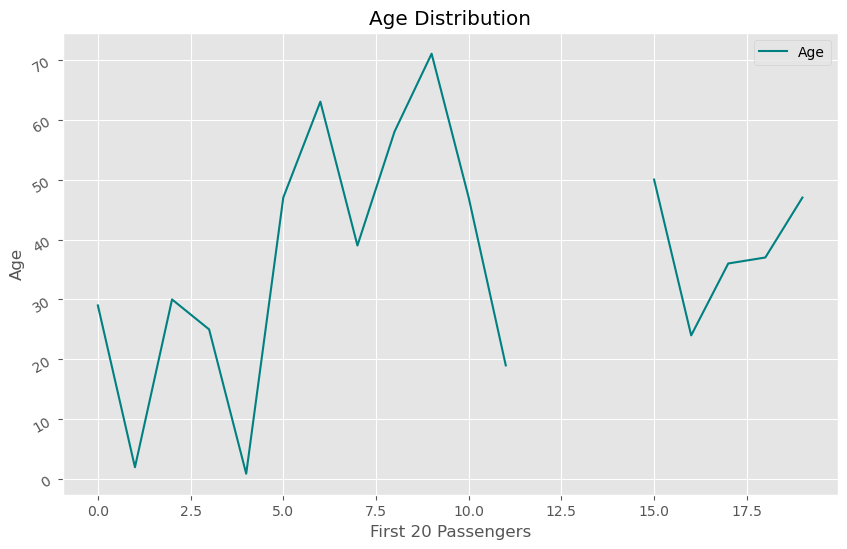

In [45]:
# 45) Age distribution plot (first 20 passengers)
df_plot = df.head(20).copy()
style.use('ggplot')
plt.figure(figsize=(10, 6))
plt.title('Age Distribution')
plt.xlabel('First 20 Passengers')
plt.ylabel('Age')
plt.yticks(rotation=30)
df_plot['Age'].plot(color='teal')
plt.legend()
plt.show()


